In [1]:
# !pip install matplotlib

In [2]:
import torch
from torch import nn, optim

In [3]:
import numpy as np

In [4]:
import pandas as pd

In [5]:
import math

In [1]:
import matplotlib.pyplot as plt

## Categorias
1 - Spam
0 - Não Spam

In [7]:
dados = pd.DataFrame( {
    "X1": [3, 0, 6, 2], # Quantidade de palavras suspeitas
    "X2": [1, 2, 5, 3], # Quantidade de links
    "Y": [0, 0, 1, 1]   # Spam ou Não Spam
})
dados

,X1,X2,Y
0,3,1,0
1,0,2,0
2,6,5,1
3,2,3,1


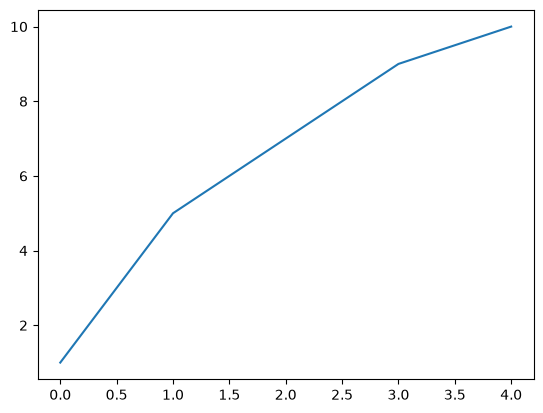

In [2]:
# plt.plot( [1, 5, 7, 9, 10] )
# plt.show()

In [8]:
modelo = nn.Sequential(
    nn.Linear(in_features = 2, out_features = 1),
    nn.Sigmoid()
)
modelo

Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): Sigmoid()
)

In [9]:
perda = nn.BCELoss()
perda

BCELoss()

In [10]:
otimizador = optim.SGD( modelo.parameters(), lr = 0.01)
otimizador

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [11]:
dados[["X1", "X2"]]

,X1,X2
0,3,1
1,0,2
2,6,5
3,2,3


In [12]:
entrada = torch.tensor( [dados["X1"], dados["X2"]], dtype=torch.float32 )
entrada

tensor([[3., 0., 6., 2.],
        [1., 2., 5., 3.]])

In [13]:
saida = torch.tensor( [dados["Y"]], dtype=torch.float32 )
saida

tensor([[0., 0., 1., 1.]])

In [14]:
saida.detach().numpy()

array([[0., 0., 1., 1.]], dtype=float32)

In [15]:
epocas = 50
perdas = []
for epoca in range( epocas ):
    y_hat = modelo( entrada.T )
    loss = perda(y_hat, saida.T)
    perdas.append( loss.tolist() )
    print(loss)
    otimizador.zero_grad()
    loss.backward()
    otimizador.step()

tensor(0.7634, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7556, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7485, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7422, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7364, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7313, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7266, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7224, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7185, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7151, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7119, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7091, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7065, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7041, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.7019, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6999, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6980, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6964, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6948, grad_fn=<Bina

In [16]:
modelo( torch.tensor( [ 0., 0. ] ))

tensor([0.5791], grad_fn=<SigmoidBackward0>)

In [3]:
perdas = [0.7634022235870361,
 0.7555673122406006,
 0.748511552810669,
 0.7421550750732422,
 0.7364252209663391,
 0.731255829334259,
 0.7265873551368713,
 0.7223659753799438,
 0.7185440063476562,
 0.7150781154632568,
 0.7119302153587341,
 0.7090660929679871,
 0.7064552903175354,
 0.7040707468986511,
 0.7018884420394897,
 0.6998869180679321,
 0.6980472803115845,
 0.6963525414466858,
 0.6947876811027527,
 0.6933391094207764,
 0.6919951438903809,
 0.6907451748847961,
 0.6895794868469238,
 0.6884896159172058,
 0.6874682307243347,
 0.6865085363388062,
 0.6856043934822083,
 0.6847503185272217,
 0.6839416027069092,
 0.6831738352775574,
 0.6824430823326111,
 0.6817460060119629,
 0.6810791492462158,
 0.6804399490356445,
 0.6798257827758789,
 0.6792342662811279,
 0.6786633729934692,
 0.67811119556427,
 0.6775761246681213,
 0.6770564913749695,
 0.676551103591919,
 0.6760586500167847,
 0.6755778789520264,
 0.6751077771186829,
 0.6746475696563721,
 0.6741964221000671,
 0.6737533211708069,
 0.6733177900314331,
 0.6728891134262085,
 0.6724668145179749]

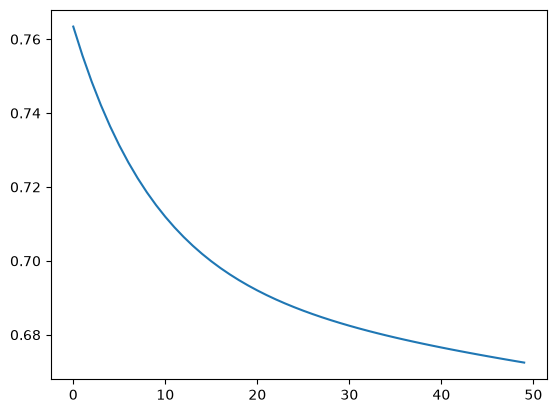

In [4]:
plt.plot( perdas )
plt.show()